# Unit 2: Random variable modelling

Discrete and continuous random variables: generate samples, compare **empirical** against **theoretical** PMF / PDF, and compare empirical against analytical mean and variance.

**Definitions used**

* Discrete: PMF $p(x)=P(X=x)$, $E[X]=\sum_x x\,p(x)$, $\operatorname{Var}(X)=E[X^2]-(E[X])^2$
* Continuous: PDF $f(x)\ge0$ with $\int f=1$, $P(a\le X\le b)=\int_a^b f(x)\,dx$, $E[X]=\int x f(x)\,dx$, $\operatorname{Var}(X)=\int (x-\mu)^2 f(x)\,dx$

| Distribution | $E[X]$ | $\operatorname{Var}(X)$ |
|---|---|---|
| Binomial$(n,p)$ | $np$ | $np(1-p)$ |
| Fair die (discrete uniform on 1..6) | $7/2$ | $35/12$ |
| Poisson$(\lambda)$ | $\lambda$ | $\lambda$ |
| Geometric$(p)$ (trials until first success) | $1/p$ | $(1-p)/p^2$ |
| Uniform$(a,b)$ | $(a+b)/2$ | $(b-a)^2/12$ |
| Normal$(\mu,\sigma^2)$ | $\mu$ | $\sigma^2$ |
| Exponential(rate $\lambda$) | $1/\lambda$ | $1/\lambda^2$ |

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import quad

rng = np.random.default_rng(42)
N = 100_000

## 1. Discrete random variables: empirical vs theoretical PMF

In [ ]:
def compare_discrete(name, samples, support, pmf, ax):
    """Print the empirical-vs-theoretical table and draw the two PMFs side by side."""
    support = np.asarray(support)
    pmf = np.asarray(pmf)

    emp_pmf = np.array([(samples == k).mean() for k in support])   # relative frequencies

    E_theory = np.sum(support * pmf)                               # E[X]   = sum x p(x)
    Var_theory = np.sum(support ** 2 * pmf) - E_theory ** 2        # Var(X) = E[X^2] - (E[X])^2
    E_emp = samples.mean()
    Var_emp = samples.var()                                        # ddof=0, matches the definition

    print(f"\n=== {name} ===")
    print(pd.DataFrame({
        "Measure": ["Expectation", "Variance", "Max |emp PMF - theo PMF|"],
        "Theoretical": [E_theory, Var_theory, 0.0],
        "Empirical": [E_emp, Var_emp, np.max(np.abs(emp_pmf - pmf))],
    }).round(4).to_string(index=False))

    w = 0.4
    ax.bar(support - w/2, pmf, w, label="Theoretical PMF", color="skyblue", edgecolor="black")
    ax.bar(support + w/2, emp_pmf, w, label="Empirical PMF", color="salmon", edgecolor="black")
    ax.set_title(name); ax.set_xlabel("x"); ax.set_ylabel("P(X = x)")
    ax.legend(); ax.grid(axis="y", alpha=0.3)
    return E_theory, Var_theory


=== Binomial(n=10, p=0.3) ===
                 Measure  Theoretical  Empirical
             Expectation          3.0     3.0027
                Variance          2.1     2.1011
Max |emp PMF - theo PMF|          0.0     0.0011
Analytical: np = 3.0 | np(1-p) = 2.1

=== Fair die ===
                 Measure  Theoretical  Empirical
             Expectation       3.5000     3.4943
                Variance       2.9167     2.9102
Max |emp PMF - theo PMF|       0.0000     0.0021
Analytical: 7/2 = 3.5 | 35/12 = 2.9167

=== Poisson(lambda=4) ===
                 Measure  Theoretical  Empirical
             Expectation          4.0     3.9982
                Variance          4.0     3.9688
Max |emp PMF - theo PMF|          0.0     0.0019
Analytical: lambda = 4 | lambda = 4

=== Geometric(p=0.25) ===
                 Measure  Theoretical  Empirical
             Expectation          4.0     3.9939
                Variance         12.0    11.9562
Max |emp PMF - theo PMF|          0.0     0.0011
A

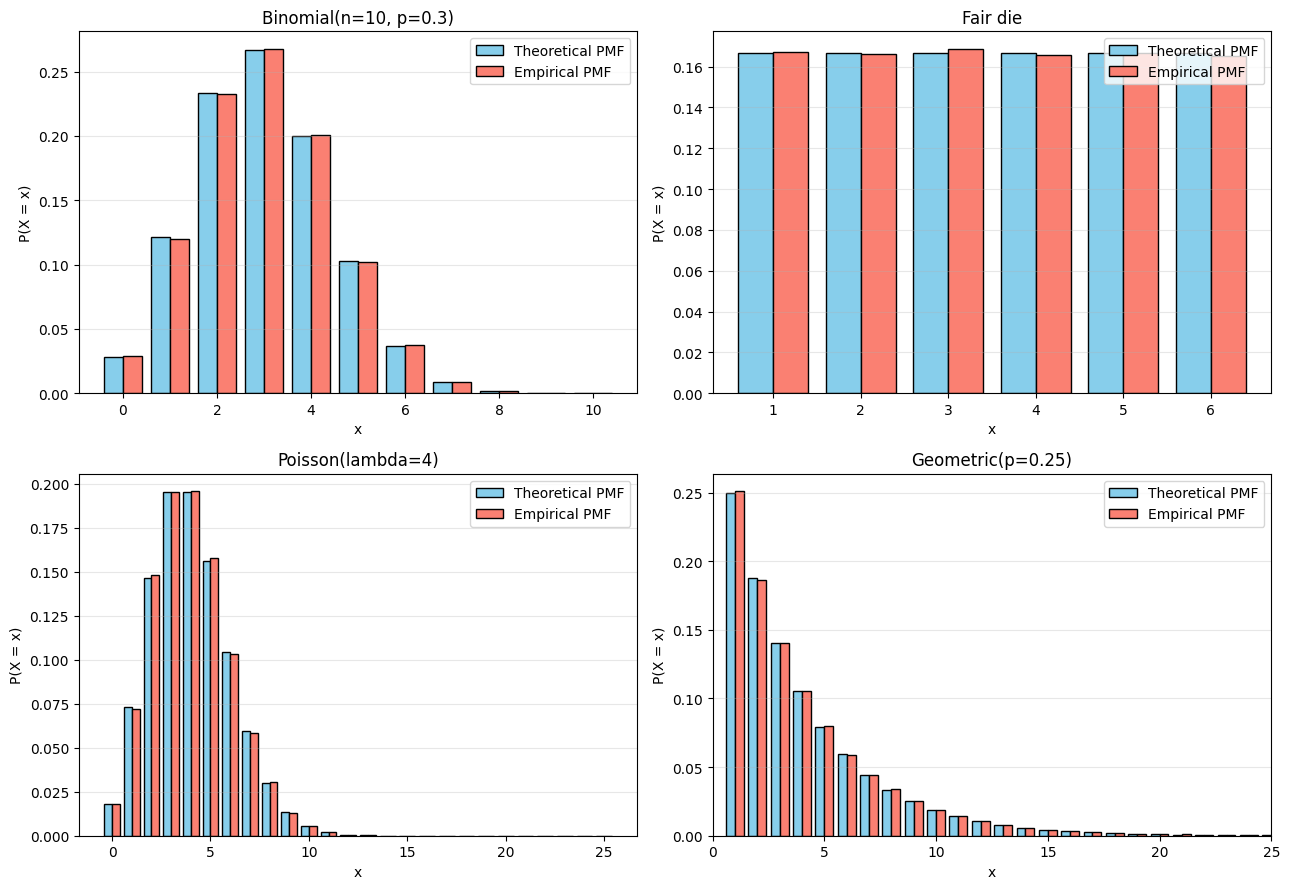

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Binomial(n=10, p=0.3)
n, p = 10, 0.3
x_bin = rng.binomial(n, p, size=N)
sup = np.arange(0, n + 1)
compare_discrete("Binomial(n=10, p=0.3)", x_bin, sup, stats.binom.pmf(sup, n, p), axes[0, 0])
print("Analytical: np =", n * p, "| np(1-p) =", round(n * p * (1 - p), 4))

# Fair die: NOTE rng.integers(low, high) EXCLUDES high, so use 7 to get 1..6
x_die = rng.integers(1, 7, size=N)
sup = np.arange(1, 7)
compare_discrete("Fair die", x_die, sup, np.full(6, 1/6), axes[0, 1])
print("Analytical: 7/2 =", 7/2, "| 35/12 =", round(35/12, 4))

# Poisson(lambda=4); support truncated at 25 (probability beyond that is negligible)
lam = 4
x_poi = rng.poisson(lam, size=N)
sup = np.arange(0, 26)
compare_discrete("Poisson(lambda=4)", x_poi, sup, stats.poisson.pmf(sup, lam), axes[1, 0])
print("Analytical: lambda =", lam, "| lambda =", lam)

# Geometric(p=0.25): number of trials until the first success, support 1, 2, 3, ...
pg = 0.25
x_geo = rng.geometric(pg, size=N)
sup = np.arange(1, 151)
compare_discrete("Geometric(p=0.25)", x_geo, sup, stats.geom.pmf(sup, pg), axes[1, 1])
axes[1, 1].set_xlim(0, 25)
print("Analytical: 1/p =", 1 / pg, "| (1-p)/p^2 =", (1 - pg) / pg ** 2)

plt.tight_layout()
plt.show()

## 2. Continuous random variables: histogram vs theoretical PDF

For a continuous variable $P(X=x)=0$, so we compare the **histogram of the samples** (with `density=True`, so its total area is 1) with the **PDF curve**. Without `density=True` the histogram shows counts and will not line up with the PDF.

Analytical mean and variance are obtained from the formulas in the table and cross-checked by numerical integration of $\int x f(x)\,dx$ and $\int x^2 f(x)\,dx-\mu^2$.

In [4]:
def compare_continuous(name, samples, pdf, support, plot_range, E_theory, Var_theory, ax):
    # numerical integration of the PDF (cross-check of the analytical formulas)
    E_num = quad(lambda t: t * pdf(t), *support)[0]
    Var_num = quad(lambda t: t ** 2 * pdf(t), *support)[0] - E_num ** 2
    area = quad(pdf, *support)[0]

    print(f"\n=== {name} ===")
    print(pd.DataFrame({
        "Measure": ["Mean", "Variance"],
        "Analytical formula": [E_theory, Var_theory],
        "Numerical integral": [E_num, Var_num],
        "Empirical (samples)": [samples.mean(), samples.var()],
    }).round(4).to_string(index=False))
    print(f"Area under PDF = {area:.4f}")

    grid = np.linspace(*plot_range, 500)
    ax.hist(samples, bins=60, density=True, alpha=0.5, edgecolor="black", label="Histogram of samples")
    ax.plot(grid, pdf(grid), "r-", lw=2, label="Theoretical PDF")
    ax.set_title(name); ax.set_xlabel("x"); ax.set_ylabel("Density")
    ax.legend(); ax.grid(alpha=0.3)


=== Uniform(2, 8) ===
 Measure  Analytical formula  Numerical integral  Empirical (samples)
    Mean                 5.0                 5.0               5.0107
Variance                 3.0                 3.0               3.0142
Area under PDF = 1.0000

=== Normal(mu=5, sigma=2) ===
 Measure  Analytical formula  Numerical integral  Empirical (samples)
    Mean                   5                 5.0               5.0020
Variance                   4                 4.0               3.9893
Area under PDF = 1.0000

=== Exponential(rate=0.5) ===
 Measure  Analytical formula  Numerical integral  Empirical (samples)
    Mean                 2.0                 2.0               2.0059
Variance                 4.0                 4.0               4.0240
Area under PDF = 1.0000


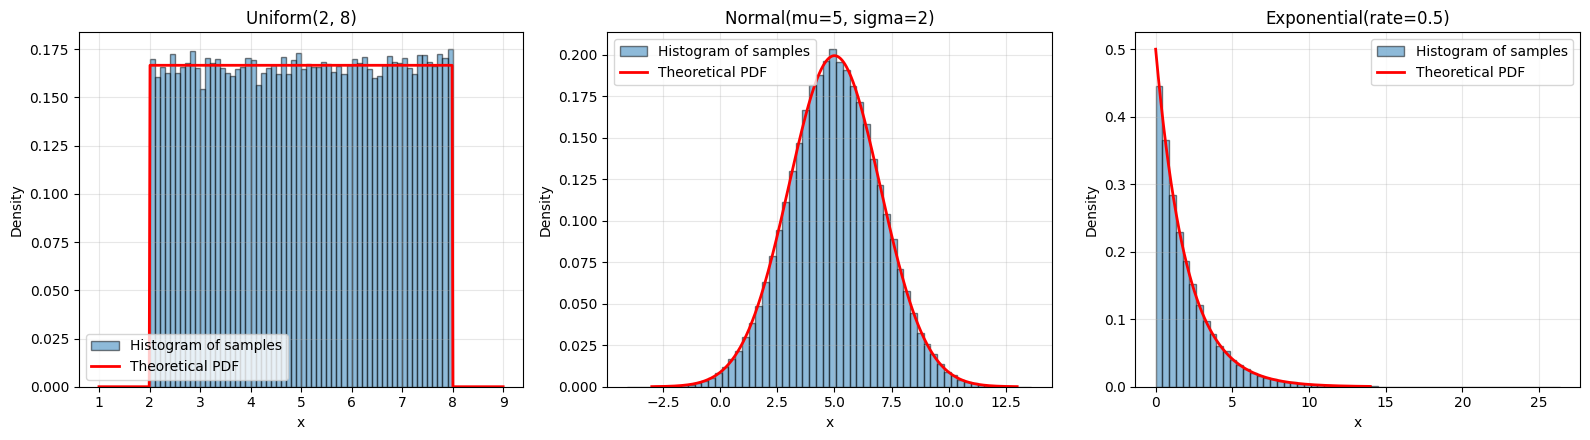

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Uniform(a=2, b=8): numpy takes (low, high); scipy takes loc=a, scale=b-a
a, b = 2, 8
x_uni = rng.uniform(a, b, size=N)
compare_continuous("Uniform(2, 8)", x_uni, stats.uniform(loc=a, scale=b - a).pdf,
                   support=(a, b), plot_range=(a - 1, b + 1),
                   E_theory=(a + b) / 2, Var_theory=(b - a) ** 2 / 12, ax=axes[0])

# Normal(mu=5, sigma=2): numpy and scipy both take the STANDARD DEVIATION, not the variance
mu, sigma = 5, 2
x_nor = rng.normal(mu, sigma, size=N)
compare_continuous("Normal(mu=5, sigma=2)", x_nor, stats.norm(mu, sigma).pdf,
                   support=(-np.inf, np.inf), plot_range=(mu - 4 * sigma, mu + 4 * sigma),
                   E_theory=mu, Var_theory=sigma ** 2, ax=axes[1])

# Exponential with RATE lambda=0.5: numpy / scipy take scale = 1/lambda
lam = 0.5
x_exp = rng.exponential(scale=1 / lam, size=N)
compare_continuous("Exponential(rate=0.5)", x_exp, stats.expon(scale=1 / lam).pdf,
                   support=(0, np.inf), plot_range=(0, 14),
                   E_theory=1 / lam, Var_theory=1 / lam ** 2, ax=axes[2])

plt.tight_layout()
plt.show()

**Probability is an area, not a height.** For $X\sim N(5,2^2)$, $P(3\le X\le7)=F(7)-F(3)$ where $F$ is the CDF. Compare with the fraction of samples falling in $[3,7]$:

In [6]:
theory = stats.norm(mu, sigma).cdf(7) - stats.norm(mu, sigma).cdf(3)
empirical = np.mean((x_nor >= 3) & (x_nor <= 7))
print(f"P(3 <= X <= 7): theoretical = {theory:.4f} | empirical = {empirical:.4f}")

P(3 <= X <= 7): theoretical = 0.6827 | empirical = 0.6834


## 3. Effect of changing the parameters

* Normal: $\mu$ **shifts** the curve, $\sigma$ controls the **spread** (a larger $\sigma$ gives a lower, wider curve because the area stays 1).
* Exponential: a larger rate $\lambda$ means a smaller mean $1/\lambda$ and a faster decay.
* Uniform: the interval $[a,b]$ sets both the location and the width, and the height is $1/(b-a)$.

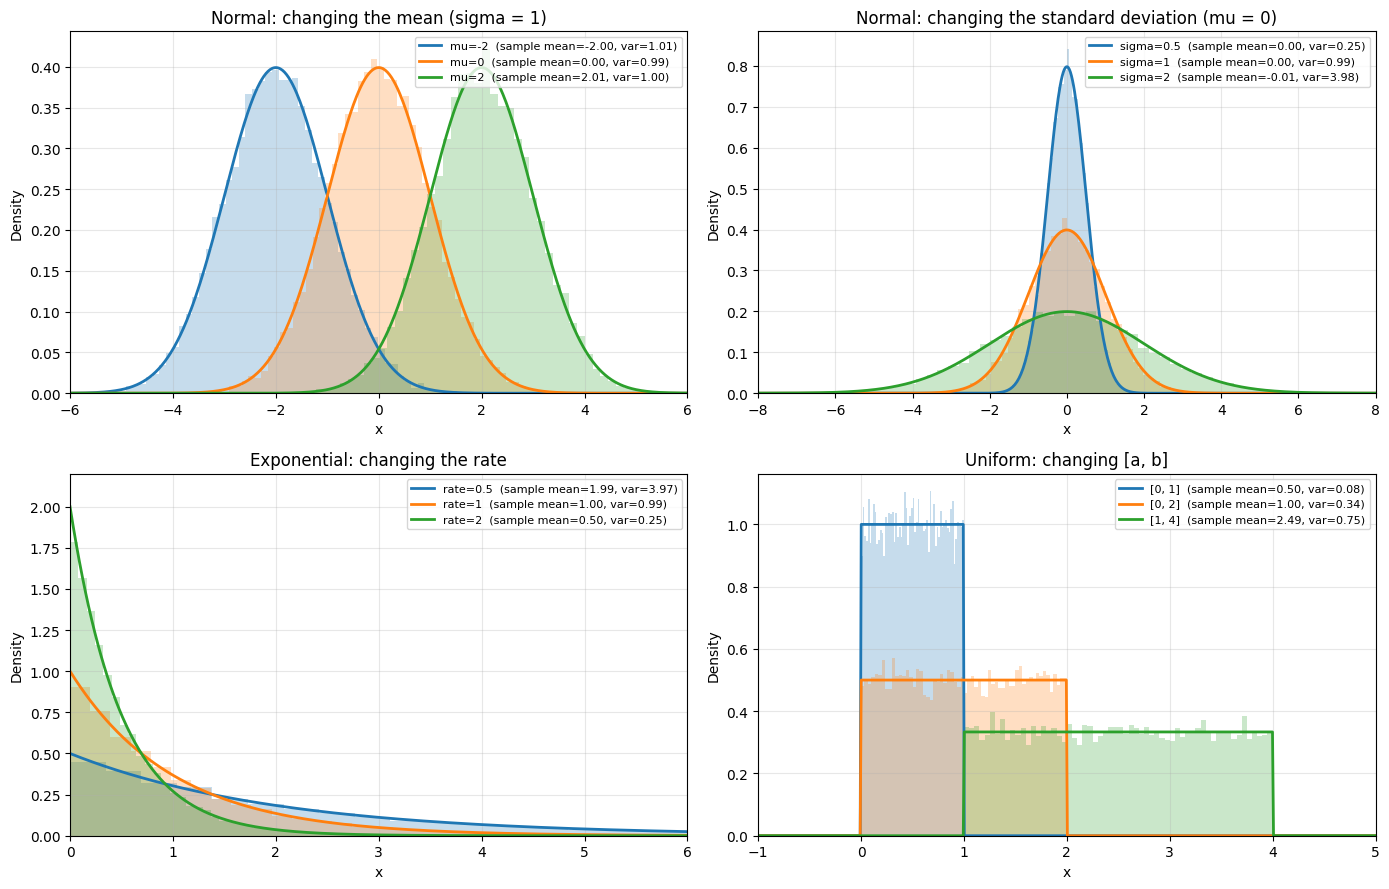

In [7]:
def panel(ax, title, configs, xlim):
    grid = np.linspace(*xlim, 600)
    for label, sampler, pdf in configs:
        s = sampler(20_000)
        line, = ax.plot(grid, pdf(grid), lw=2, label=f"{label}  (sample mean={s.mean():.2f}, var={s.var():.2f})")
        ax.hist(s, bins=60, density=True, alpha=0.25, color=line.get_color())
    ax.set_title(title); ax.set_xlim(*xlim); ax.grid(alpha=0.3); ax.legend(fontsize=8)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

panel(axes[0, 0], "Normal: changing the mean (sigma = 1)", [
    (f"mu={m}", lambda n, m=m: rng.normal(m, 1, n), stats.norm(m, 1).pdf) for m in (-2, 0, 2)
], (-6, 6))

panel(axes[0, 1], "Normal: changing the standard deviation (mu = 0)", [
    (f"sigma={sg}", lambda n, sg=sg: rng.normal(0, sg, n), stats.norm(0, sg).pdf) for sg in (0.5, 1, 2)
], (-8, 8))

panel(axes[1, 0], "Exponential: changing the rate", [
    (f"rate={r}", lambda n, r=r: rng.exponential(1 / r, n), stats.expon(scale=1 / r).pdf) for r in (0.5, 1, 2)
], (0, 6))
axes[1, 0].set_ylim(0, 2.2)

panel(axes[1, 1], "Uniform: changing [a, b]", [
    (f"[{lo}, {hi}]", lambda n, lo=lo, hi=hi: rng.uniform(lo, hi, n), stats.uniform(lo, hi - lo).pdf)
    for lo, hi in ((0, 1), (0, 2), (1, 4))
], (-1, 5))

for ax in axes.ravel():
    ax.set_xlabel("x"); ax.set_ylabel("Density")
plt.tight_layout()
plt.show()

## 4. Law of large numbers: empirical mean and variance converge with sample size

In [8]:
rows = []
for size in [10, 100, 1_000, 10_000, 100_000]:
    xn = rng.normal(5, 2, size)
    xb = rng.binomial(10, 0.3, size)
    rows.append([size, xn.mean(), xn.var(), xb.mean(), xb.var()])

print(pd.DataFrame(rows, columns=["Sample size", "Normal mean (->5)", "Normal var (->4)",
                                   "Binomial mean (->3)", "Binomial var (->2.1)"]).round(4).to_string(index=False))

 Sample size  Normal mean (->5)  Normal var (->4)  Binomial mean (->3)  Binomial var (->2.1)
          10             4.6896            2.6189               2.3000                1.2100
         100             4.6505            3.4230               2.9200                1.8336
        1000             4.9725            4.3442               3.0000                2.1720
       10000             4.9997            4.0534               2.9857                2.0995
      100000             5.0032            3.9943               2.9941                2.1041


## Debugging checklist for random-variable code

1. `rng.integers(1, 7)` / `np.random.randint(1, 7)` exclude the upper bound; `random.randint(1, 6)` includes it.
2. `np.var` uses `ddof=0` (divide by $n$); `ddof=1` divides by $n-1$. Match the formula the question asks for.
3. Exponential: numpy / scipy take `scale = 1/rate`, not the rate. Normal: they take the standard deviation, not the variance.
4. Histogram versus PDF needs `density=True`; for a PMF compare relative frequencies (count / n), never raw counts.
5. Use the same support for empirical and theoretical PMFs (`np.arange(0, n+1)` for a binomial).
6. Geometric: scipy and numpy count the trial on which the first success occurs (support starts at 1), so $E=1/p$.
7. `np.random.binomial(n=1, p=p)` is a Bernoulli sample; `size=` is the number of samples, `n=` is the number of trials per sample.